# Fase 03 : Aplicación del entorno de simulación y entrenamiento
**Institución:** Universidad Católica Boliviana "San Pablo"  
**Programa:** Maestría en Ciencia de Datos  
**Autor:** Carlos Andrés Pérez Guzmán  
**Fecha:** Octubre 2026  

---
**Entorno y Objetivos del Notebook**
> **Nota:** Aplicación del entorno de simulación y entrenamiento del modelo
* **Fase del Proyecto:** Tercera fase fase
* **Core Tech Stack:** `Python` (Programación general para ciencia de datos)
---

<h3 style="color:#05856d">1. Librerías</h3>
<hr>

In [11]:
import polars as pl
import s_01_functions as fn_01
from pyprojroot import here
from s_02_stock_env import EntornoInventario
from stable_baselines3 import PPO
from datetime import date

<h3 style="color:#05856d">2. Carga de información</h3>
<hr>

In [12]:
df_02 = pl.read_parquet(source = here()/'01_cleaned_data'/'df_02.parquet')
df_02.glimpse()

Rows: 17239
Columns: 11
$ bottle_volume_ml  <enum> 1750, 1750, 1750, 1750, 1750, 1750, 1750, 1750, 1750, 1750
$ category_name      <cat> CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES
$ im_desc            <cat> BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET, BLACK VELVET
$ item_no            <i64> 11788, 11788, 11788, 11788, 11788, 11788, 11788, 11788, 11788, 11788
$ ordered_on        <date> 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02, 2026-01-02
$ pack               <i64> 6, 6, 6, 6, 6, 6, 6, 6, 6, 6
$ period_ordered_on  <cat> 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01, 2026-01
$ product_code       <str> 'PRD_000205', 'PRD_000205', 'PRD_000205', 'PRD_000205', 'PRD_000205

<h3 style="color:#05856d">3. Preparación de datos</h3>
<hr>

<h4 style="color:#05856d">3.1. Ajustar la demanda y otras variables</h4>

In [13]:
# Creación de calendario
df_calendario = pl.DataFrame(
    {'ordered_on': pl.date_range(
        start = df_02['ordered_on'].min(), 
        end = df_02['ordered_on'].max(),
        interval = '1d',
        eager = True)} )

# Acoplar la demanda al caledario previamente creado
df_demanda_continua = (
    df_calendario
    .join( other = df_02.group_by('ordered_on').agg(pl.sum('sales_bottles').alias('demanda_diaria')),
           on = 'ordered_on', 
           how = 'left' )
    .with_columns([ pl.col('demanda_diaria').fill_null(0),                 
                    pl.col('ordered_on').dt.weekday().alias('dia_semana') ]) )

# Cantidad de botellas por pack
pack_u = df_02['pack'][0]

# Precio unitario promedio
precio_u = (df_02['sales_dollars'] / df_02['sales_bottles']).mean()

<h4 style="color:#05856d">3.2. Datos de entrenamiento y prueba</h4>

Se divide cronológicamente los datos el dataset. Por tanto, no es necesaria una semilla aleatoria.

In [14]:
df_train = df_demanda_continua.filter(pl.col('ordered_on') < date(2026,7,1))
df_test = df_demanda_continua.filter(pl.col('ordered_on') >= date(2026,7,1))

print(f"Total de días reales en el calendario: {df_demanda_continua.height}")
print('-'*60)
print(f"Registros para el conjunto de entrenamiento (Train): {df_train.height}")
print(f"Proporción del conjunto de entrenamiento: {df_train.height/df_demanda_continua.height:.2f}")
print('-'*60)
print(f"Registros para prueba (Test): {df_test.height}")
print(f"Proporción del conjunto de prueba: {df_test.height / df_demanda_continua.height:.2f}")

Total de días reales en el calendario: 242
------------------------------------------------------------
Registros para el conjunto de entrenamiento (Train): 180
Proporción del conjunto de entrenamiento: 0.74
------------------------------------------------------------
Registros para prueba (Test): 62
Proporción del conjunto de prueba: 0.26


In [ ]:

print("🏗️ Configurando Entorno de ENTRENAMIENTO...")
env_training = EntornoInventario(
    df_demanda_diaria = df_train,          
    precio_unitario = precio_u,  
    tamano_pack = pack_u )

print("🏗️ Configurando Entorno de PRUEBAS...")
env_testing = EntornoInventario(
    df_demanda_diaria = df_test,     
    precio_unitario = precio_u,  
    tamano_pack = pack_u )

🏗️ Configurando Entorno de ENTRENAMIENTO...
🏗️ Configurando Entorno de PRUEBAS...


In [64]:
# 1. Configurar la arquitectura de la Red Neuronal
print('🧠 Inicializando la Red Neuronal PPO (Entrenamiento sobre df_train)...')
# Usamos MlpPolicy (Perceptrón Multicapa), ideal para vectores de números.
modelo_ppo_final = PPO(
    'MlpPolicy', 
    env_training,         # <--- Entrenamos SOLO con el entorno de entrenamiento
    verbose = 1,            # Para ver el progreso en la consola
    seed = 42,              # Semilla de reproducibilidad académica
    ent_coef = 0.01,        # Coeficiente de entropía: fomenta la exploración de estrategias
    learning_rate = 0.0002  # Tasa de aprendizaje estable
)

# 2. El Entrenamiento Intensivo
print('\n🚀 Iniciando entrenamiento definitivo de 1,000,000 de timesteps.')
print('   Esto tomará unos minutos. ¡Paciencia, ingeniero!')
modelo_ppo_final.learn(total_timesteps = 1000000)

# 3. Guardar el "Cerebro" entrenado
modelo_ppo_final.save('agente_ppo_black_velvet_final')
print('\n✅ ¡Agente entrenado y guardado exitosamente como "agente_ppo_black_velvet_final.zip"!')

# Cerrar el entorno de entrenamiento para liberar memoria
env_training.close()

🧠 Inicializando la Red Neuronal PPO (Entrenamiento sobre df_train)...
Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.

🚀 Iniciando entrenamiento definitivo de 1,000,000 de timesteps.
   Esto tomará unos minutos. ¡Paciencia, ingeniero!
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 180      |
|    ep_rew_mean     | -4.1e+06 |
| time/              |          |
|    fps             | 2533     |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 2048     |
---------------------------------
---------------------------------------
| rollout/                |           |
|    ep_len_mean          | 180       |
|    ep_rew_mean          | -4.18e+06 |
| time/                   |           |
|    fps                  | 1830      |
|    iterations           | 2         |
|    time_elapsed         | 2         |
|    total_timesteps      | 4096      |
| train/           

In [ ]:


# 2. Unir la demanda y rellenar los días muertos con 0
df_demanda_continua = (
    df_calendario
    .join(
        df_02.group_by('ordered_on').agg(pl.sum('sales_bottles').alias('demanda_diaria')),
        on='ordered_on', 
        how='left'
    )
    .with_columns([
        pl.col('demanda_diaria').fill_null(0),                 # Los días sin ventas se vuelven 0
        pl.col('ordered_on').dt.weekday().alias('dia_semana')  # Calculamos el día de la semana (1-7)
    ])
)

# 3. Train / Test Split (80% / 20%)
total_dias = df_demanda_continua.height
punto_corte = int(total_dias * 0.80)

df_train = df_demanda_continua.head(punto_corte)
df_test = df_demanda_continua.tail(total_dias - punto_corte)

print(f"📊 Total de días reales en el calendario: {total_dias}")
print(f"🧠 Días para Entrenamiento (Train): {df_train.height}")
print(f"🎯 Días para Evaluación (Test): {df_test.height}")

df_demanda_continua.head(5)

🧠 Despertando al Agente PPO Final para la simulación Monte Carlo...
📊 Ejecutando 50 simulaciones estocásticas en el conjunto de PRUEBA (Test)...

📈 RESULTADOS DEL CONTRASTE DE MEDIAS (50 Simulaciones)
💰 Media Beneficio PPO: $774,420.90 (Desv: $99,140.14)
💰 Media Beneficio EOQ: $354,467.39 (Desv: $225,744.95)
------------------------------------------------------------
⚖️ T-Statistic: 11.9230
🔬 P-Value:     3.0421e-18
✅ CONCLUSIÓN: El Agente PPO es estadísticamente SUPERIOR al EOQ (p < 0.05).


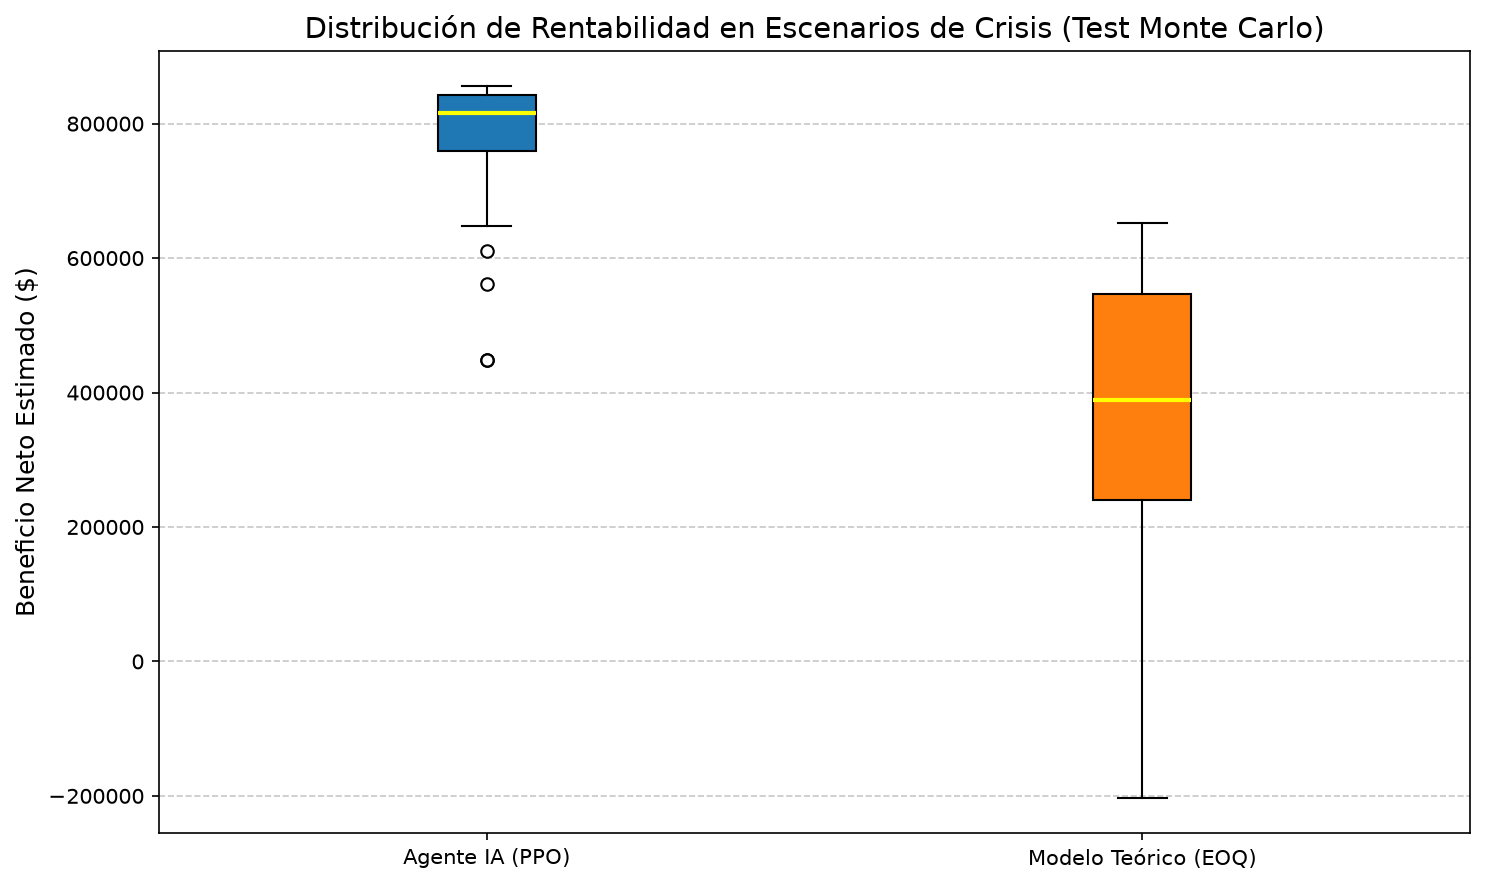

In [70]:
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3 import PPO
import scipy.stats as stats

print("🧠 Despertando al Agente PPO Final para la simulación Monte Carlo...")
modelo_cargado = PPO.load('agente_ppo_black_velvet_final')

num_simulaciones = 50
resultados_ppo = []
resultados_eoq = []

# Parámetros del EOQ Teórico
q_optimo_packs = 640
punto_reorden_botellas = 4200

print(f"📊 Ejecutando {num_simulaciones} simulaciones estocásticas en el conjunto de PRUEBA (Test)...")

for i in range(num_simulaciones):
    semilla = 42 + i
    
    # --- 1. SIMULACIÓN PPO ---
    obs, info = env_testing.reset(seed=semilla)
    terminado = False
    beneficio_ppo_iter = 0.0
    
    while not terminado:
        action, _ = modelo_cargado.predict(obs, deterministic=True)
        obs, recompensa, terminado, truncado, info = env_testing.step(action)
        beneficio_ppo_iter += recompensa
    
    resultados_ppo.append(beneficio_ppo_iter)
    
    # --- 2. SIMULACIÓN EOQ (CORREGIDA) ---
    obs, info = env_testing.reset(seed=semilla)
    terminado = False
    beneficio_eoq_iter = 0.0
    
    pedido_en_camino = False
    inventario_anterior = obs[0]
    
    while not terminado:
        inventario_actual = obs[0]
        
        # Detectar si el camión llegó (el inventario da un salto positivo frente al día anterior)
        if inventario_actual > inventario_anterior:
            pedido_en_camino = False
            
        # Política rígida de EOQ con restricción de tránsito real
        if inventario_actual <= punto_reorden_botellas and not pedido_en_camino:
            action = q_optimo_packs
            pedido_en_camino = True  # Bloqueamos nuevos pedidos hasta que este llegue
        else:
            action = 0
            
        inventario_anterior = inventario_actual
        obs, recompensa, terminado, truncado, info = env_testing.step(action)
        beneficio_eoq_iter += recompensa
        
    resultados_eoq.append(beneficio_eoq_iter)

# --- ANÁLISIS ESTADÍSTICO ---
resultados_ppo = np.array(resultados_ppo)
resultados_eoq = np.array(resultados_eoq)

t_stat, p_value = stats.ttest_ind(resultados_ppo, resultados_eoq, equal_var=False)

print("\n" + "=" * 60)
print("📈 RESULTADOS DEL CONTRASTE DE MEDIAS (50 Simulaciones)")
print("=" * 60)
print(f"💰 Media Beneficio PPO: ${resultados_ppo.mean():,.2f} (Desv: ${resultados_ppo.std():,.2f})")
print(f"💰 Media Beneficio EOQ: ${resultados_eoq.mean():,.2f} (Desv: ${resultados_eoq.std():,.2f})")
print("-" * 60)
print(f"⚖️ T-Statistic: {t_stat:.4f}")
print(f"🔬 P-Value:     {p_value:.4e}")

if p_value < 0.05:
    if resultados_ppo.mean() > resultados_eoq.mean():
        print("✅ CONCLUSIÓN: El Agente PPO es estadísticamente SUPERIOR al EOQ (p < 0.05).")
    else:
        print("⚠️ CONCLUSIÓN: El EOQ es estadísticamente SUPERIOR al PPO (p < 0.05).")
else:
    print("🤷‍♂️ CONCLUSIÓN: No hay diferencia estadísticamente significativa entre los modelos.")
print("=" * 60)

# --- GRÁFICO BOXPLOT PARA LA TESIS ---
plt.figure(figsize=(10, 6))

cajas = plt.boxplot([resultados_ppo, resultados_eoq], 
            patch_artist=True, boxprops=dict(facecolor='#1f77b4', color='black'),
            medianprops=dict(color='yellow', linewidth=2))

cajas['boxes'][1].set_facecolor('#ff7f0e')
plt.xticks([1, 2], ['Agente IA (PPO)', 'Modelo Teórico (EOQ)'])

plt.title('Distribución de Rentabilidad en Escenarios de Crisis (Test Monte Carlo)', fontsize=14)
plt.ylabel('Beneficio Neto Estimado ($)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('boxplot_montecarlo_tesis_corregido.png', dpi=300)
plt.show()

Seríe de tiempo de la demanda

In [22]:
import polars as pl

# 1. Extraer las fechas límite de tu dataset original
fecha_inicio = df_02['ordered_on'].min()
fecha_fin = df_02['ordered_on'].max()

# 2. Crear un calendario continuo (sin saltarse ni un solo día)
df_calendario = pl.DataFrame({
    'ordered_on': pl.date_range(fecha_inicio, fecha_fin, '1d', eager=True)
})

# 3. Unir la demanda y rellenar los días muertos con 0
df_demanda_continua = (
    df_calendario
    .join(
        df_02.group_by('ordered_on').agg(pl.sum('sales_bottles').alias('demanda_diaria')),
        on='ordered_on', 
        how='left'
    )
    .with_columns([
        pl.col('demanda_diaria').fill_null(0),                 # Los días sin ventas se vuelven 0
        pl.col('ordered_on').dt.weekday().alias('dia_semana')  # Calculamos el día de la semana (1-7)
    ])
)

print(f"Días de ventas con tickets: {df_02['ordered_on'].n_unique()}")
print(f"Serie de tiempo continua (Corregida): {df_demanda_continua.height} días reales de operación.")

df_demanda_continua.head(10)

Días de ventas con tickets: 115
Serie de tiempo continua (Corregida): 149 días reales de operación.


ordered_on,demanda_diaria,dia_semana
date,i64,i8
2026-01-02,1026,5
2026-01-03,0,6
2026-01-04,114,7
2026-01-05,833,1
2026-01-06,1137,2
2026-01-07,644,3
2026-01-08,649,4
2026-01-09,952,5
2026-01-10,0,6


Extraer parámetros específicos para el modelo base

precio_medio,pack
f64,i64
17.237854,6


Ejecutar el modelo base

In [25]:
eoq_cajas = fn_01.eoq_baseline(
    df_demanda_diaria = df_demanda_continua, 
    df_param = df_temp, 
    dias_year = 365, 
    costo_pedido_S = 50.0, 
    tasa_mantenimiento_i = 0.20 )

--------------------------------------------------------------
RESULTADOS DEL MODELO BASE (EOQ)
--------------------------------------------------------------
Demanda Anual Estimada (D)       : 392,147 botellas
Costo de Mantenimiento Anual (H) : $ 3.45 por botella
Costo Fijo por Pedido (S)        : $ 50.00
EOQ Óptimo Teórico               : 3,373 botellas
EOQ Ajustado a "packs"           : 563 packs (de 6 botellas) 
--------------------------------------------------------------


<h3 style="color:#05856d">4. Entrenamiento</h3>
<hr>

In [ ]:

# 3. Instanciar tu entorno versión 6.0 (Escenario Crisis 2026)
print("🏗️ Configurando entorno logístico con blindaje para crisis (42,000 botellas)...")
env_training = EntornoInventario(
    df_demanda_diaria = df_demanda_continua,
    precio_unitario = df_temp[0,0],  
    tamano_pack = df_temp[0,0],              
    ventana_historica = 7,
    max_capacidad_almacen = 42000         # 30 días de cobertura
)

# 4. Configurar la arquitectura de la Red Neuronal
print('\n🧠 Inicializando la Red Neuronal PPO...')
# Usamos MlpPolicy (Perceptrón Multicapa), ideal para vectores de números como el nuestro.
modelo_ppo_crisis = PPO(
    'MlpPolicy', 
    env_training, 
    verbose=1,            # Para ver el progreso en la consola
    seed=42,              # Semilla de reproducibilidad académica
    ent_coef=0.01,        # Coeficiente de entropía: obliga a la IA a explorar estrategias raras
    learning_rate=0.0002  # Tasa de aprendizaje (pasos pequeños para no desestabilizarse)
)

# 5. El Entrenamiento Intensivo
print('\n🚀 Iniciando entrenamiento de 1,000,000 de timesteps. Esto puede tomar unos minutos...')
modelo_ppo_crisis.learn(total_timesteps=1000000)

# 6. Guardar el "Cerebro" entrenado
modelo_ppo_crisis.save('agente_ppo_black_velvet_v6')
print('\n✅ ¡Agente entrenado y guardado exitosamente como "agente_ppo_black_velvet_v6.zip"!')

# Cerrar el entorno de entrenamiento para liberar memoria
env_training.close()

🏗️ Configurando entorno logístico con blindaje para crisis (42,000 botellas)...

🧠 Inicializando la Red Neuronal PPO...
Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.

🚀 Iniciando entrenamiento de 1,000,000 de timesteps. Esto puede tomar unos minutos...
----------------------------------
| rollout/           |           |
|    ep_len_mean     | 149       |
|    ep_rew_mean     | -1.35e+07 |
| time/              |           |
|    fps             | 2609      |
|    iterations      | 1         |
|    time_elapsed    | 0         |
|    total_timesteps | 2048      |
----------------------------------
---------------------------------------
| rollout/                |           |
|    ep_len_mean          | 149       |
|    ep_rew_mean          | -1.37e+07 |
| time/                   |           |
|    fps                  | 1730      |
|    iterations           | 2         |
|    time_elapsed         | 2         |
|    total_timesteps      | 4

🧠 Despertando al Agente PPO V6...
📊 Simulando comportamiento operativo...


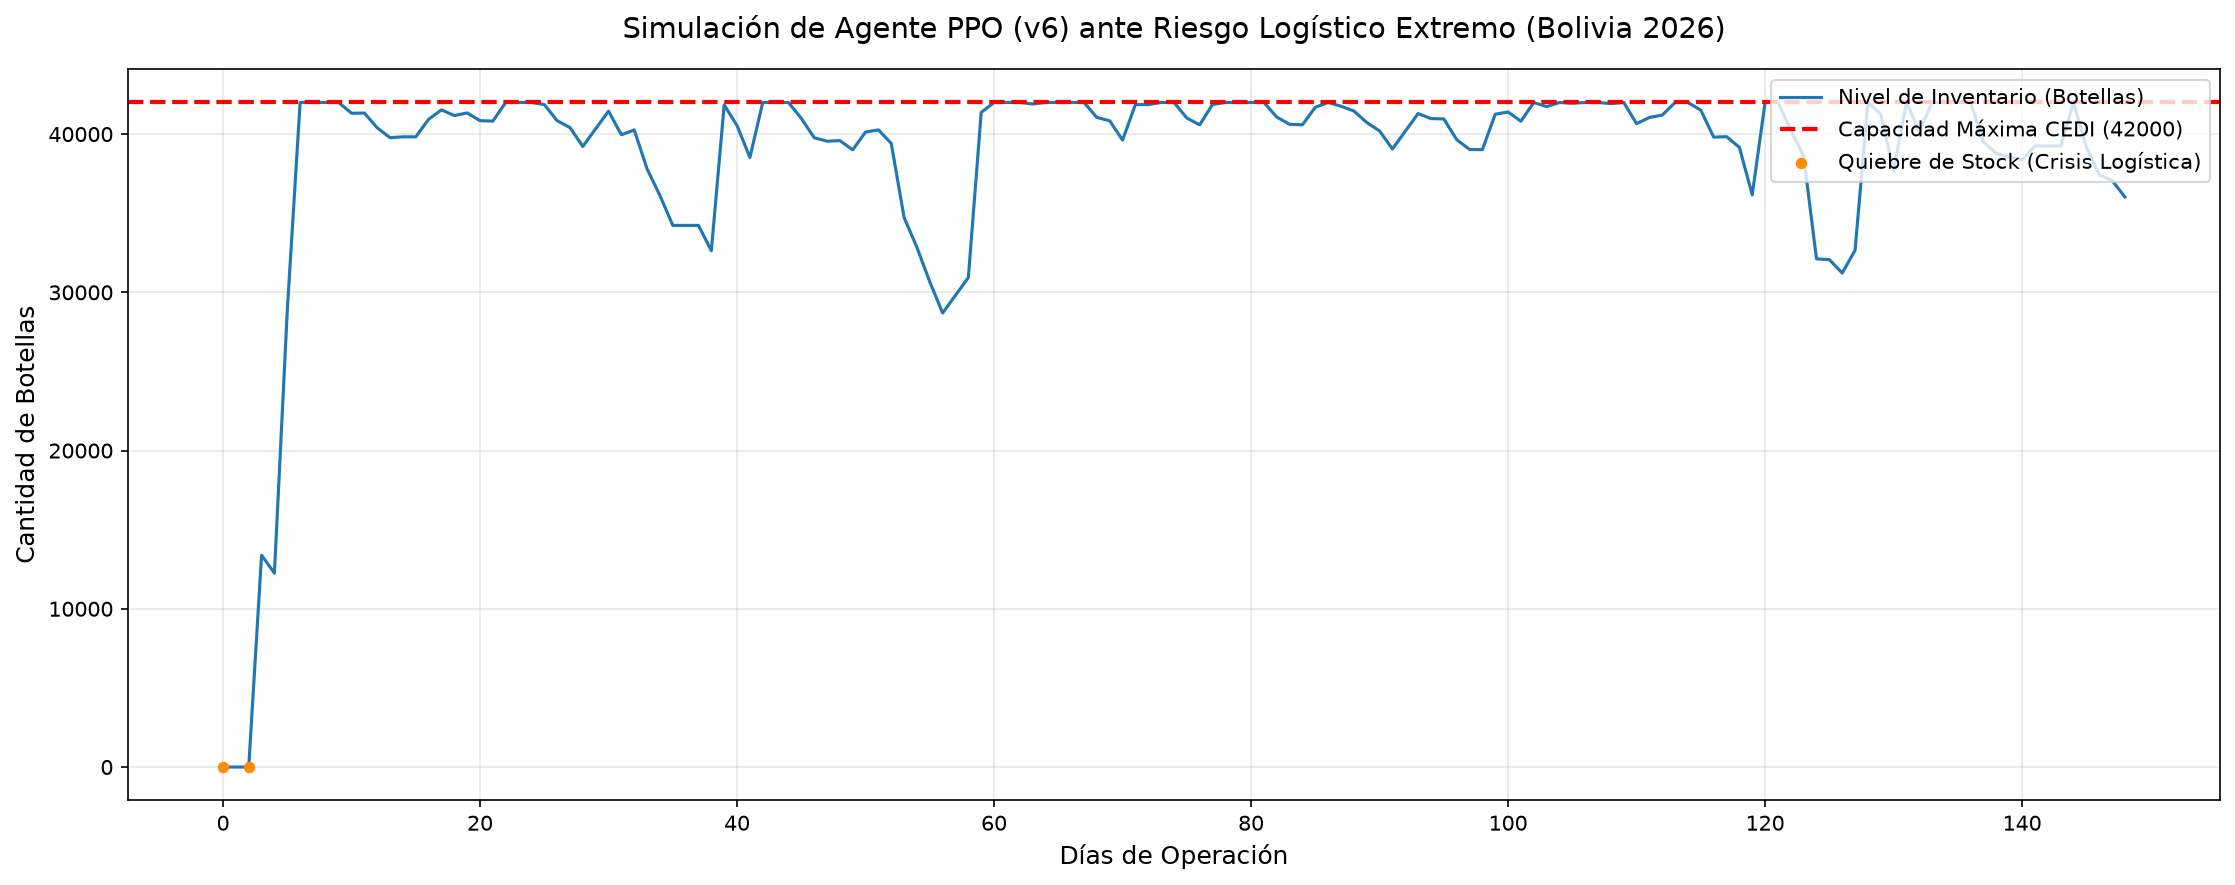


✅ ¡Simulación finalizada y gráfica 'grafica_ppo_crisis_black_velvet.png' guardada!


In [ ]:
import matplotlib.pyplot as plt
from stable_baselines3 import PPO

# 1. Cargar el Agente Entrenado
print("🧠 Despertando al Agente PPO V6...")
modelo_cargado = PPO.load('agente_ppo_black_velvet_v6')

# 2. Reiniciar el entorno para una prueba en "Producción"
# Usamos el mismo env_training que ya tienes instanciado en tu memoria
obs, info = env_training.reset(seed=42) # Usamos semilla para que el gráfico sea reproducible
terminado = False

# Listas para guardar la historia de la simulación
historial_inventario = []
historial_pedidos = []
historial_quiebres = []

print("📊 Simulando comportamiento operativo...")

# 3. Bucle de Simulación (El agente toma el control)
while not terminado:
    # deterministic=True obliga a la IA a usar su mejor estrategia aprendida, sin azar
    action, _states = modelo_cargado.predict(obs, deterministic=True)
    
    # Avanzamos un día en el entorno
    obs, recompensa, terminado, truncado, info = env_training.step(action)
    
    # Guardamos los registros del día
    historial_inventario.append(obs[0])               # Nivel de inventario al final del día
    historial_pedidos.append(action * env_training.pack) # Botellas pedidas hoy
    historial_quiebres.append(info['quiebre'])        # Demanda que no pudimos cubrir hoy

# 4. Graficar los Resultados
plt.figure(figsize=(15, 6))

# Línea del nivel de inventario
plt.plot(historial_inventario, label='Nivel de Inventario (Botellas)', color='#1f77b4', linewidth=1.5)

# Línea punteada roja para la capacidad máxima del CEDI
plt.axhline(y=env_training.max_capacidad, color='red', linestyle='--', linewidth=2, 
            label=f'Capacidad Máxima CEDI ({env_training.max_capacidad})')

# Identificar y marcar los días con quiebre de stock (Pérdidas millonarias)
dias_quiebre = [i for i, q in enumerate(historial_quiebres) if q > 0]
valores_quiebre = [historial_inventario[i] for i in dias_quiebre]
if dias_quiebre:
    plt.scatter(dias_quiebre, valores_quiebre, color='darkorange', zorder=5, s=20, 
                label='Quiebre de Stock (Crisis Logística)')

# Formato estético para la Tesis
plt.title('Simulación de Agente PPO (v6) ante Riesgo Logístico Extremo (Bolivia 2026)', fontsize=14, pad=15)
plt.xlabel('Días de Operación', fontsize=12)
plt.ylabel('Cantidad de Botellas', fontsize=12)
plt.legend(loc='upper right')
plt.grid(alpha=0.3)
plt.tight_layout()

# Guardar la gráfica en alta calidad para adjuntar al documento de Word
plt.savefig('grafica_ppo_crisis_black_velvet.png', dpi=300)
plt.show()

print("\n✅ ¡Simulación finalizada y gráfica 'grafica_ppo_crisis_black_velvet.png' guardada!")

In [28]:
# 1. Reiniciar el entorno usando la misma semilla de la gráfica
obs, info = env_training.reset(seed=42)
terminado = False

# 2. Variables acumuladoras contables
total_ingresos = 0.0
total_costo_ordenes = 0.0
total_costo_mantenimiento = 0.0
total_costo_quiebres = 0.0
total_costo_exceso = 0.0
total_beneficio_neto = 0.0

print("💵 Auditando métricas financieras del Agente PPO...")

# 3. Bucle Financiero
while not terminado:
    # El agente toma su decisión determinística
    action, _ = modelo_cargado.predict(obs, deterministic=True)
    obs, recompensa, terminado, truncado, info = env_training.step(action)
    
    # Reconstrucción de la contabilidad del día basada en tu entorno
    ingresos_dia = info['ventas'] * env_training.p
    costo_quiebre_dia = info['quiebre'] * env_training.k
    costo_orden_dia = env_training.S if action > 0 else 0.0
    costo_mantenimiento_dia = (obs[0] ** 1.05) * env_training.h
    
    # Despejamos la penalización por exceso usando la recompensa final
    costo_exceso_dia = ingresos_dia - costo_orden_dia - costo_mantenimiento_dia - costo_quiebre_dia - recompensa
    
    # Acumulamos
    total_ingresos += ingresos_dia
    total_costo_ordenes += costo_orden_dia
    total_costo_mantenimiento += costo_mantenimiento_dia
    total_costo_quiebres += costo_quiebre_dia
    total_costo_exceso += max(0, costo_exceso_dia) # max(0) evita micro-errores de decimales en Python
    total_beneficio_neto += recompensa

# 4. Imprimir el Estado de Resultados
print("\n" + "=" * 50)
print("📊 ESTADO DE RESULTADOS: SIMULACIÓN DE CRISIS 2026")
print("=" * 50)
print(f"💰 (+) Ingresos por Ventas:       ${total_ingresos:,.2f}")
print(f"📉 (-) Costos Administrativos:    ${total_costo_ordenes:,.2f}")
print(f"📦 (-) Costos de Almacenaje:      ${total_costo_mantenimiento:,.2f}")
print(f"🚨 (-) Multas por Quiebre (5x):   ${total_costo_quiebres:,.2f}")
print(f"🗑️ (-) Multas por Exceso CEDI:    ${total_costo_exceso:,.2f}")
print("-" * 50)
print(f"🏆 BENEFICIO NETO (Recompensa):   ${total_beneficio_neto:,.2f}")
print("=" * 50)

💵 Auditando métricas financieras del Agente PPO...

📊 ESTADO DE RESULTADOS: SIMULACIÓN DE CRISIS 2026
💰 (+) Ingresos por Ventas:       $2,739,818.93
📉 (-) Costos Administrativos:    $7,450.00
📦 (-) Costos de Almacenaje:      $1,917,456.00
🚨 (-) Multas por Quiebre (5x):   $5,700.00
🗑️ (-) Multas por Exceso CEDI:    $1,228,165.06
--------------------------------------------------
🏆 BENEFICIO NETO (Recompensa):   $-418,951.67


In [30]:
# 1. Parámetros del modelo teórico clásico (EOQ)
# (Si en tu tesis calculaste un EOQ y ROP exactos para Black Velvet, cámbialos aquí)
q_optimo_packs = 640           # Cantidad fija a pedir (ej. 640 cajas = 3840 botellas)
punto_reorden_botellas = 4200  # ROP: Cuándo pedir (ej. cuando queden botellas para ~3 días)

# 2. Reiniciar el entorno con la MISMA semilla para clonar la crisis exacta
obs, info = env_training.reset(seed=42)
terminado = False

# Variables acumuladoras contables para el EOQ
eoq_ingresos = 0.0
eoq_costo_ordenes = 0.0
eoq_costo_mantenimiento = 0.0
eoq_costo_quiebres = 0.0
eoq_costo_exceso = 0.0
eoq_beneficio_neto = 0.0

print("⚖️ Evaluando el Modelo Teórico (EOQ) ante la Crisis 2026...")

# 3. Bucle de Simulación Clásica
while not terminado:
    inventario_actual = obs[0]
    
    # POLÍTICA DETERMINÍSTICA (La regla del libro de texto)
    # Si el inventario cruza el umbral de peligro, lanza una orden fija.
    if inventario_actual <= punto_reorden_botellas:
        action = q_optimo_packs
    else:
        action = 0
        
    # Ejecutamos la acción ciega en el entorno de crisis
    obs, recompensa, terminado, truncado, info = env_training.step(action)
    
    # Contabilidad del día
    ingresos_dia = info['ventas'] * env_training.p
    costo_quiebre_dia = info['quiebre'] * env_training.k
    costo_orden_dia = env_training.S if action > 0 else 0.0
    costo_mantenimiento_dia = (inventario_actual ** 1.05) * env_training.h
    costo_exceso_dia = ingresos_dia - costo_orden_dia - costo_mantenimiento_dia - costo_quiebre_dia - recompensa
    
    # Acumulamos
    eoq_ingresos += ingresos_dia
    eoq_costo_ordenes += costo_orden_dia
    eoq_costo_mantenimiento += costo_mantenimiento_dia
    eoq_costo_quiebres += costo_quiebre_dia
    eoq_costo_exceso += max(0, costo_exceso_dia)
    eoq_beneficio_neto += recompensa

# 4. Imprimir el Estado de Resultados del Colapso
print("\n" + "=" * 50)
print("💥 ESTADO DE RESULTADOS: MODELO TEÓRICO (EOQ)")
print("=" * 50)
print(f"💰 (+) Ingresos por Ventas:       ${eoq_ingresos:,.2f}")
print(f"📉 (-) Costos Administrativos:    ${eoq_costo_ordenes:,.2f}")
print(f"📦 (-) Costos de Almacenaje:      ${eoq_costo_mantenimiento:,.2f}")
print(f"🚨 (-) Multas por Quiebre (5x):   ${eoq_costo_quiebres:,.2f}")
print(f"🗑️ (-) Multas por Exceso CEDI:    ${eoq_costo_exceso:,.2f}")
print("-" * 50)
print(f"📉 BENEFICIO NETO (Colapso):      ${eoq_beneficio_neto:,.2f}")
print("=" * 50)

⚖️ Evaluando el Modelo Teórico (EOQ) ante la Crisis 2026...

💥 ESTADO DE RESULTADOS: MODELO TEÓRICO (EOQ)
💰 (+) Ingresos por Ventas:       $2,630,010.53
📉 (-) Costos Administrativos:    $850.00
📦 (-) Costos de Almacenaje:      $1,006,349.50
🚨 (-) Multas por Quiebre (5x):   $37,550.95
🗑️ (-) Multas por Exceso CEDI:    $140,034.58
--------------------------------------------------
📉 BENEFICIO NETO (Colapso):      $1,492,609.12
